In this notebook, I will be collecting and storing data from Facebook's Graph API documentation.  
I will be collecting GraphAPI changelogs, then parsing them with a function that usese REGEX to locate points of interest.  
These points of interest are the changes within the changelog.   
I then want to classify these changes as: 'new features', 'deprications', 'changes' and compare the distribution of these classes with other versions.  

My first goal will be to create two functions:

Function 1 will call a request and get the markdown file of a changelog.  
Function 2 will parse that changelog, pull out the points of interest, classify them, and load them into a data frame. 

In [90]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import re
import html

In [91]:
CLIENT = "WebDataScience/1.0 (micah.crowe@colorado.edu)"
HEADERS = {"User-Agent": f"{CLIENT} python-requests/{requests.__version__}"}

In [92]:
import os
os.makedirs("data", exist_ok=True)
clean2_df.sample(20, random_state=1).to_csv("data/sample_cleaned.csv", index=False)

In [93]:
def get_markdown(version):

    version_url = f"{core_url}version{version}.md"
    
    response = requests.get(version_url, headers=HEADERS, timeout=10)

    response.raise_for_status()

    text = response.text

    return text

In [94]:
def old_parse_changelog(text):
    version = ""
    product = ""
    release_date = ""
    section = ""
    rows = []
    current_change = None

    for line in text.splitlines():

        if line.startswith("# Version"):
            match = re.search(r"Version (\d+\.\d+)", line)
            version = match.group(1)

        elif line.startswith("## "):
            product = line.replace("## ", "").strip()
            section = ""
            current_change = {
                "version": version,
                "product": product,
                "release_date": release_date,
                "section": "",
                "subsection": "",
                "body": "",
                }
            rows.append(current_change)

        elif line.startswith("**Released**"):
            match = re.search(r"([A-Z][a-z]+ \d{1,2}, \d{4})", line)
            release_date = match.group(1)

        elif line.startswith("### "):
            section = line.replace("### ", "").strip()
            current_change = {
                "version": version,
                "product": product,
                "release_date": release_date,
                "section": section,
                "subsection": "",
                "body": "",
            }
            rows.append(current_change)

        elif line.startswith("#### "):
            subsection = line.replace("#### ", "").strip()
            current_change = {
                "version": version,
                "product": product,
                "release_date": release_date,
                "section": section,
                "subsection": subsection,
                "body": "",
            }
            rows.append(current_change)

        elif current_change is not None:
            current_change["body"] = current_change["body"] + line + "\n"

    df = pd.DataFrame(rows)
    df = df[df["body"].str.strip() != ""]
    df["release_date"] = pd.to_datetime(df["release_date"])
    return df

In [95]:
def clean_text(text):
    text = re.sub(r"\s*&#123;#.*?&#125;", "", text)   # fix 1: remove the anchors like {#gapi-v2-9}
    text = html.unescape(text)                         # turn leftover &#123; into real { }
    return text

def parse_changelog(text, version):                    # fix 2: version is passed in, so no need to scrape it from the text
    text = clean_text(text)
    product = ""
    release_date = ""
    section = ""
    rows = []
    current_change = None

    for line in text.splitlines():

        if line.strip() == "---":                      # fix 3: skip divider lines which got stored in the previous version 
            continue

        elif line.lstrip("#").strip().startswith("Version "):   # skips the version heading which got caught in the last function 
            continue

        elif line.startswith("## "):
            product = line.replace("## ", "").strip()
            section = ""
            current_change = {
                "version": version,
                "product": product,
                "release_date": release_date,
                "section": "",
                "subsection": "",
                "body": "",
            }
            rows.append(current_change)

        elif line.startswith("**Released**"):
            match = re.search(r"([A-Z][a-z]+ \d{1,2}, \d{4})", line)
            release_date = match.group(1)

        elif line.startswith("### "):
            section = line.replace("### ", "").strip()
            current_change = {
                "version": version,
                "product": product,
                "release_date": release_date,
                "section": section,
                "subsection": "",
                "body": "",
            }
            rows.append(current_change)

        elif line.startswith("#### "):
            subsection = line.replace("#### ", "").strip()
            current_change = {
                "version": version,
                "product": product,
                "release_date": release_date,
                "section": section,
                "subsection": subsection,
                "body": "",
            }
            rows.append(current_change)

        elif current_change is not None:
            current_change["body"] = current_change["body"] + line + "\n"

    df = pd.DataFrame(rows)
    df = df[df["body"].str.strip() != ""]
    df["release_date"] = pd.to_datetime(df["release_date"])
    df = df.reset_index(drop=True)
    return df

In [96]:
# When this function runs it should return a df with key data from the changelogs.
# This includes the version, which API product is getting changed, the section of the change and its subsection, and the body (description)

In [97]:
df1 = parse_changelog(get_markdown(11.0), 11.0)
df1

,version,product,release_date,section,subsection,body
0,11.0,Graph API,2021-06-08,Consumer Apps,Access Levels,_Applies to all versions._\n\nIn the coming we...
1,11.0,Graph API,2021-06-08,Developer Support,,\nWe have released the [Facebook for Business ...
2,11.0,Graph API,2021-06-08,Facebook Analytics,Deprecation,_Applies to all versions._\n\nFacebook Analyti...
3,11.0,Graph API,2021-06-08,Instagram Basic Display API,Access Token Debugger,\n_Applies to all versions._\n\nThe [access to...
4,11.0,Graph API,2021-06-08,Instagram Basic Display API,API Versioning,\n_Applies to all versions._\n\nThe API now su...
5,11.0,Graph API,2021-06-08,Instagram Basic Display API,App Scoped User IDs,\n_Applies to version 11.0+._\n\nApp-scoped us...
6,11.0,Graph API,2021-06-08,Instagram Basic Display API,Time-based Pagination,\n_Applies to v11.0+_.\n\nAdded [`since`](http...
7,11.0,Graph API,2021-06-08,Instagram Graph API,Like Counts,\n_Applies to v11.0+. Will apply to all versio...
8,11.0,Graph API,2021-06-08,Instagram Graph API,Time-based Pagination,\n_Applies to v11.0+_.\n\nAdded [`since`](http...
9,11.0,Graph API,2021-06-08,Instant Experiences,Templates,\n_Applies to v11.0+._\n\n[Instant Experience ...


In [98]:
versions_sample = ['2.7','2.8','2.9','2.10','2.11','2.12','3.0', '3.1', '3.2', '3.3', '4.0', '5.0', '6.0', '7.0', '8.0', '9.0','10.0']
# This sample contains versions from 2016 all the way to 2021
# I picked this date range specifically because I wanted some data from before Meta's scandal and the data from after will show their response

frames = []
for v in versions_sample:
    df = parse_changelog(get_markdown(v), v)   
    frames.append(df)

In [99]:
df_sample = pd.concat(frames, ignore_index=True)
df_sample.sample(20)

,version,product,release_date,section,subsection,body
152,3.0,Graph API,2018-05-01,90-Day Breaking Changes,All Apps,\n- **Development Mode** — Apps in development...
26,2.8,,2016-10-05,Deprecations v2.8,,\n- [Open Graph](#gapi-deprecate-opengraph-v2-...
222,4.0,Marketing API,2019-07-29,Product Catalogs,,\n- `GET /{business_asset_group_ID}/contained_...
200,3.3,Marketing API,2019-04-30,Ads Insights and Measurement,,\n- Changed rate limits at the ad account leve...
91,2.10,Marketing API,2017-07-18,,,\n\n- [New Features](#mapi-new)\n- [Changes](#...
85,2.10,Graph API,2017-07-18,Deprecations,Events,\n- **`GET /{event-id}/videos`** — This edge h...
234,4.0,Marketing API,2019-07-29,Ads Insights,,\nDeprecated `video_avg_percent_watched_action...
22,2.8,,2016-10-05,New Features v2.8,Resumable Upload API,"\n- Upload files a small piece at a time, allo..."
11,2.7,,2016-07-13,New Features v2.7,,\n- No New Features.\n\n\n
247,6.0,Marketing API,2020-02-03,,,"\n\nFor Marketing API, v6.0, there are no new ..."


In [100]:
# This new sample of data is much cleaner than the previous one, but I still need to do some work
# The function pulls out the table of contents from the changelogs and mistakenly marks them as changes, I will have to remove them
# The product labels are very inconsistent and I may just end up ignoring them since I cannot find a way to consistently pull the correct product


In [101]:
def is_link_list(body):
    for line in body.splitlines():
        line = line.strip()
        if line == "":
            continue
        starts_like_link = line.startswith("- [") or line.startswith("[") # this line finds if the body of the change starts with '[', which the table of contents do 
        if not (starts_like_link and "](#" in line):
            return False
    return True

In [102]:
clean1_df_sample = df_sample[~df_sample["body"].apply(is_link_list)]
clean2_df = clean1_df_sample[~clean1_df_sample["body"].str.strip().str.startswith("No ")] # removes entries with 'no' such as 'no 90 day breaking changes' - which is not a change in the api
clean2_df.sample(20)


,version,product,release_date,section,subsection,body
331,10.0,Marketing API,2021-02-23,Targeting,Lookalike Audiences,"\n**Warning:** **UPDATED APRIL 28, 2021:** The..."
215,4.0,Webhooks,2019-07-29,Page Feed,,\n_This change applies to v4.0+._\n\nThe `like...
186,3.2,Marketing API,2018-10-23,Ads Insights and Measurement,,"\nWe deprecated cost per engagement metrics, c..."
110,2.11,Graph API,2017-11-07,Deprecations,Webhooks,\n- **User Topic** — The following fields have...
312,9.0,Graph API,2020-11-10,Instagram,Ads,\n_Applies to v9.0+_\n\n[IG Media](https://dev...
113,2.11,Graph API,2017-11-07,90-Day Breaking Changes,Groups,\n- **`/group/videos`** — This edge now requir...
251,7.0,Graph API,2020-05-05,Messenger,Page Messenger Profiles,\n_This change applies to v7.0+._\n\nThe `home...
59,2.9,Graph API,2017-04-18,90-Day Breaking Changes,Video,\n- **Insights Edge** - All `paid` and `organi...
216,4.0,Webhooks,2019-07-29,Performance Improvements,,\n_This change applies to all versions._\n\nWe...
82,2.10,Graph API,2017-07-18,Changes,User,\n- **[`GET /{user-id}/conversations`](https:/...


In [103]:
# My next task will be classifying these changes into different groups. 
# This will require me to define terms that are assosiated with groups, then search for those terms in the changelog descriptions

In [104]:
removal_terms = [
    "no longer",
    "deprecat",       
    "discontinu",
    "remov",           
    "will fail",
    "ending its support",
    "be deleted",
] # Will flag a change as *removal*

restriction_terms = [
    "must",
    "will not be returned",
    "omitted",
    "limiting access",
    "revoked",
    "by default",
    "now only",
    "will receive an error",
    "app review",
    "advanced access",
    "standard access",
] # Will flag a change as *restriction*

addition_terms = [
    "released",
    "introduc",
    "added",
    "now supports",
    "now available",
    "new endpoint",
    "new feature",
] # Will flag a change as *addition*

modification_terms = [
    "changed",
    "changing",
    "renamed",
    "updated",
    "replaced",
    "will always use",
] # Will flag a change as *modification*

In [105]:
# This function will pull from the term lists above, then use those terms against a text input and find if it contains those terms

def contains_any(text, terms):
    for term in terms:
        if term in text:
            return True
    return False

In [106]:
# This function takes a piece of text, then checks it with the various term lists, and returns which classification it belives the change is

def label_change(section, body):
    s = section.lower()
    if "deprecat" in s:
        return "removal"
    if "new feature" in s:
        return "addition"

    text = body.lower()
    if contains_any(text, removal_terms):
        return "removal"
    elif contains_any(text, restriction_terms):
        return "restriction"
    elif contains_any(text, addition_terms):
        return "addition"
    elif contains_any(text, modification_terms):
        return "modification"
    else:
        return "other"



In [107]:
# This will now combine those changes into the dataframe and I will begin to be able to make visualizations and answer questions
# Getting to this point took so much time, finally time to have fun! (hopefully)
clean2_df["change_type"] = clean2_df.apply(
    lambda row: label_change(row["section"], row["body"]), axis=1
)
clean2_df["change_type"].value_counts()

C:\Users\Apuzz\AppData\Local\Temp\ipykernel_30040\465823777.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean2_df["change_type"] = clean2_df.apply(


change_type
removal         148
other            61
addition         44
restriction      17
modification     14
Name: count, dtype: int64

In [127]:
counts = pd.crosstab(clean2_df["version"], clean2_df["change_type"])
counts = counts.reindex(versions_sample)   # puts versions in order 
shares = counts.div(counts.sum(axis=1), axis=0)   # percent of each version's changes
counts

change_type,addition,modification,other,removal,restriction
version,,,,,
2.7,4,1,1,6,0
2.8,5,0,2,7,0
2.9,11,0,0,13,1
2.10,2,2,6,7,0
2.11,6,3,5,9,0
2.12,0,2,1,3,0
3.0,5,1,2,12,3
3.1,0,1,1,7,1
3.2,2,1,2,4,1


In [129]:
shares

change_type,addition,modification,other,removal,restriction
version,,,,,
2.7,0.333333,0.083333,0.083333,0.500000,0.000000
2.8,0.357143,0.000000,0.142857,0.500000,0.000000
2.9,0.440000,0.000000,0.000000,0.520000,0.040000
2.10,0.117647,0.117647,0.352941,0.411765,0.000000
2.11,0.260870,0.130435,0.217391,0.391304,0.000000
2.12,0.000000,0.333333,0.166667,0.500000,0.000000
3.0,0.217391,0.043478,0.086957,0.521739,0.130435
3.1,0.000000,0.100000,0.100000,0.700000,0.100000
3.2,0.200000,0.100000,0.200000,0.400000,0.100000


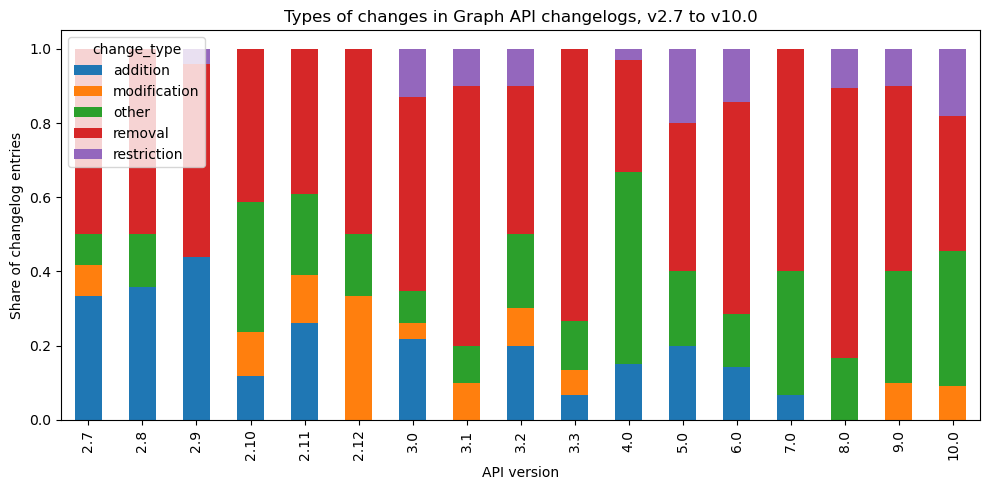

In [141]:
import os
os.makedirs("figures", exist_ok=True)

shares.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Types of changes in Graph API changelogs, v2.7 to v10.0")
plt.xlabel("API version")
plt.ylabel("Share of changelog entries")
plt.savefig("figures/change_types_by_version.png", dpi=200)
plt.tight_layout()
plt.show()

In [143]:
print(os.getcwd())


C:\Users\Apuzz\Web Data Final Project 2026
